<a href="https://colab.research.google.com/github/George7531/Portfolio_Management/blob/main/Group_19296_MScFE_652_Portfolio_Management_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Code Book:**

##Group Work Project # 2
###GROUP NUMBER: 19296
####Group members:

- Duy Vo
- George Immanuel
- Sing Chun Lee


#### Import Required Packages

In [1]:
# This block import all required python packages for running this notebook
import numpy as np                      # numpy
import matplotlib.pyplot as plt         # for plotting
import math                             # math lib
import pandas as pd                     # for storing data in the DataFrame
import pandas_datareader.data as web
from scipy.optimize import minimize     # for minimizing
import yfinance as yf                   # yfinance library
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list # for clustering
from scipy.spatial.distance import squareform # error function

# Data Preperation and Description

We chose 'TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM', and we split the data set at 2025-10-01. i.e., training: 2024-01-10 to 2025-09-30, and testing: 2025-10-01 to 2025-12-31.

In [8]:
# Define parameters
tickers = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']
BENCHMARK = "^GSPC"
in_sample_start = '2024-01-01' # updated to 2024-01-01 as we agreed
in_sample_end = '2025-09-30'
out_sample_start = '2025-10-01'
out_sample_end = '2025-12-31'
kfold_start = '2024-01-01'
kfold_end = '2025-12-31'
num_trading_days = 252 # Following the standard, assume we have 252 trading days a year

# 1. Download using yfinance
# Using auto_adjust=False
raw_data = yf.download(
    tickers + [BENCHMARK],
    start='2023-12-25', # Include an additional week before our sample start date
    end='2026-01-01', # the end is exclusive, we should use 2026-01-01 so 2025-12-31 is included
    auto_adjust=False
)

adj_close = raw_data['Close']

# Calculate simple daily percentage returns
daily_returns = adj_close.pct_change().dropna(how='all').dropna()

# Normalize the data for alignment with Fama-French data
daily_returns.index = pd.to_datetime(daily_returns.index).tz_localize(None).normalize()

# In-Sample and Out-of-Sample subsets
returns_in_sample = daily_returns.loc[in_sample_start:in_sample_end]
returns_out_sample = daily_returns.loc[out_sample_start:out_sample_end]
returns_kfold = daily_returns.loc[kfold_start:kfold_end]

print(f"In-Sample Observations: {len(returns_in_sample)} days")
print(f"Out-of-Sample Observations: {len(returns_out_sample)} days")
print(f"K-fold Observations: {len(returns_kfold)} days")

# 2. Download Fama-French 5-Factor Daily Data
ff5_daily = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench', start='2024-01-01', end='2026-01-01')[0]
ff5_daily.index = ff5_daily.index.to_timestamp()

# Convert from percentages to decimals
ff5_daily = ff5_daily / 100.0

# Normalize the data
ff5_daily.index = pd.to_datetime(ff5_daily.index).tz_localize(None).normalize()

# Partition factor data
ff_in_sample = ff5_daily.loc[in_sample_start:in_sample_end]
ff_out_sample = ff5_daily.loc[out_sample_start:out_sample_end]
ff_kfold_sample = ff5_daily.loc[kfold_start:kfold_end]

print("\nFama-French Data Sample:")
print(pd.concat([ff_in_sample.head(2), ff_out_sample.tail(3)]))

[*********************100%***********************]  11 of 11 completed


In-Sample Observations: 438 days
Out-of-Sample Observations: 64 days
K-fold Observations: 502 days

Fama-French Data Sample:
            Mkt-RF     SMB     HML     RMW     CMA      RF
Date                                                      
2024-01-02 -0.0070 -0.0025  0.0079  0.0067  0.0059  0.0002
2024-01-03 -0.0101 -0.0192 -0.0010  0.0036 -0.0021  0.0002
2025-12-29 -0.0041 -0.0015  0.0007  0.0032  0.0003  0.0002
2025-12-30 -0.0020 -0.0049  0.0029  0.0036  0.0014  0.0002
2025-12-31 -0.0076  0.0006 -0.0010 -0.0007 -0.0004  0.0002


# Step 4b: Improvements using Culstering

To begin, we computer the hierarchical clustering as we learned in the lessons.

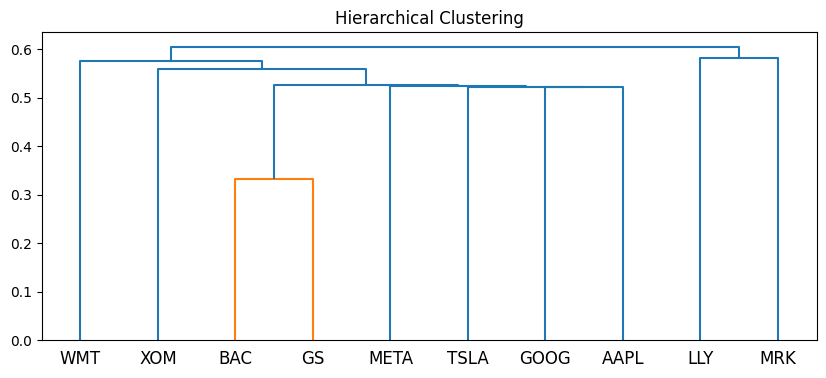

Orders:  ['WMT', 'XOM', 'BAC', 'GS', 'META', 'TSLA', 'GOOG', 'AAPL', 'LLY', 'MRK']


In [ ]:
# Hierarchical Clustering
train = returns_in_sample[tickers]
test = returns_out_sample[tickers]

# Computer the coveraince and correlation matrices
cov = train.cov()
corr = train.corr()

# Convert the correlations into distances
distances = np.sqrt((1 - corr) / 2)
np.fill_diagonal(distances.values, 0) # to itself should be 0 distance

# Single linkage hierarchical clustering
links = linkage(squareform(distances.values), method="single")

# Show the current linkages
plt.figure(figsize=(10, 4))
dendrogram(links, labels=tickers)
plt.title("Hierarchical Clustering")
plt.show()

# Order the stocks by clusters
ordered_tickers = [tickers[i] for i in leaves_list(links)]
print("Orders: ", ordered_tickers)

Now, we can compare the results. First, we compute the weights using HRP and MVO.

In [ ]:
# Compute the HRP weights through recursive bisection
hrp_weights = pd.Series(1.0, index=ordered_tickers)
clusters = [ordered_tickers]

while clusters:
  clusters = [part for group in clusters if len(group) > 1 for part in (group[:len(group)//2], group[len(group)//2:])]

  for i in range(0, len(clusters), 2):
    left, right = clusters[i], clusters[i+1]
    left_cov = cov.loc[left, left].values
    right_cov = cov.loc[right, right].values

    left_ivp = 1 / np.diag(left_cov)
    left_ivp /= left_ivp.sum()
    right_ivp = 1 / np.diag(right_cov)
    right_ivp /= right_ivp.sum()

    left_var = left_ivp @ left_cov @ left_ivp
    right_var = right_ivp @ right_cov @ right_ivp

    alpha = right_var / (right_var + left_var)

    hrp_weights.loc[left] *= alpha
    hrp_weights.loc[right] *= [1 - alpha]

# Compute MVO weights
mean = train.mean().values * num_trading_days
cov_mov = cov.values * num_trading_days
n = len(tickers)

mvo_weights = minimize(lambda w: 0.5 * (w @ cov_mov @ w) - w @ mean, np.ones(n) / n, method='SLSQP', constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1}, bounds=[(0, 1)] * n)
assert mvo_weights.success, mvo_weights.message

# Put them in a data frame
weights = pd.DataFrame({'MVO': mvo_weights.x, 'HRP': hrp_weights.reindex(tickers).values, 'Uniform': np.ones(n) / n}, index=tickers)

# Display the results in percentages
print((weights * 100).round(2))

        MVO    HRP  Uniform
TSLA  20.21   2.25     10.0
WMT    0.00  20.22     10.0
BAC    0.00   8.96     10.0
GS    34.21   4.92     10.0
LLY    0.00   6.13     10.0
MRK    0.00  12.38     10.0
GOOG   0.00  10.73     10.0
META  45.58   2.92     10.0
AAPL   0.00  12.31     10.0
XOM    0.00  19.19     10.0


Last, we used backtesting to compare the performances

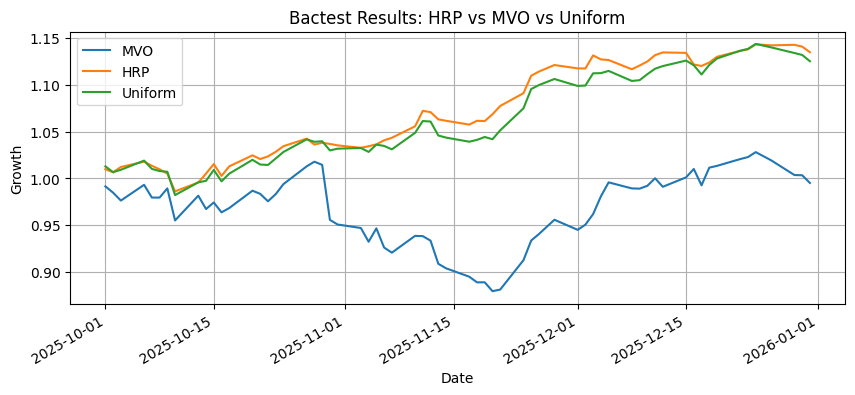

         Cumulative Return (%)  Sharpe Ratio  Max Drawdown (%)  95%-CVaR (%)  \
MVO                      -0.49         -0.17            -13.59          3.51   
HRP                      13.48          4.22             -3.12          1.28   
Uniform                  12.51          3.18             -3.61          1.51   

         Sortino Ratio  
MVO              -0.00  
HRP               0.11  
Uniform           0.08  


In [ ]:
# Compute the daily returns
portfolio_returns = test @ weights

# Cumulative growth
growth = (1 + portfolio_returns).cumprod()
growth.plot(figsize=(10, 4))
plt.title("Bactest Results: HRP vs MVO vs Uniform")
plt.ylabel("Growth")
plt.grid(True)
plt.show()

# Performance metrics
rf = ff_out_sample['RF'].reindex(test.index)

results = {}
for name in portfolio_returns.columns:
  r = portfolio_returns[name]
  excess = r - rf
  wealth = (1 + r).cumprod()
  peak = np.maximum.accumulate(np.r_[1.0, wealth.values])[1:]
  drawdown = wealth.values / peak - 1
  downside = np.minimum(excess, 0)
  var_95 = r.quantile(0.05)

  results[name] = {
      'Cumulative Return (%)': (wealth.iloc[-1] - 1) * 100,
      'Sharpe Ratio': excess.mean() / excess.std() * np.sqrt(num_trading_days),
      'Max Drawdown (%)': drawdown.min() * 100,
      '95%-CVaR (%)': -r[r <= var_95].mean() * 100,
      'Sortino Ratio': excess.mean() / np.sqrt((downside**2).mean() * np.sqrt(num_trading_days))
  }

performances = pd.DataFrame(results).T
print(performances.round(2))

Our experiment found that Hierarchical Risk Parity (HRP) significantly outperformed standard Mean-Variance Optimization (MVO) over the out-of-sample observations. HRP obtained a 13.48% cumulative return and a 4.22 Sharpe ratio, while MVO had negative returns (-0.49%) and a negative Sharpe ratio (-0.17). Therefore, it suggests that HRP indeed improves portfolio performance. However, we also included uniform weighting in the comparison, and we found that uniform weighting, in fact, performed similarly to HRP. It made us wonder if a simple uniform distribution is sufficiently good. Our experiment is limited to these ten stocks. More data could provide better interpretations.

# George's work:


# Step 4c: Detoning

Financial assets are often correlated because they are exposed to some common systematic factors, it could be recession or recent policy changes or whatever that makes all assets in the market to behave like they are all same. A simple example would be the oil syndicate deciding to change the price of fuel, since majority of vehicles use petrol/diesel for locomotion, it will simultaneously affect the prices of all assets from sandals we wear, to colab we use to write this piece down, to colors they use to make floral patterns on their porches(Indian cultural custom) likewise in times of crisis all assets from real estates, to IT stocks, to agricultural companies are affected and heavily correlated and nose dive regardless of their locations and geography in the globe.

How do we deal with this?
When we calculate the correlation matrix of asset returns, the largest eigenvalue and its corresponding eigenvector often capture this common market behaviour. This is called as the market mode. But the things is the market factor that is common among assets would overstate or misreport the actual specific dependency or correlation between companies for example lets say Nvidia and AMD dealing with semiconductors and chips they have some dependency between them that is prior to including the common market factor such as oil price was 0.5 correlation but after including the market factor it might elevate to 0.91 or some other bizzare number that obscures the actual dependency between things we measure. This is where Detoning helps.

Detoning addresses this problem by removing the contribution of the dominant market eigencomponent from the correlation matrix.This allows the remaining correlation structure to reflect more of the relative relationships between assets rather than their common market exposure (López de Prado, 2020).

The steps to detoning are way simpler with statistical packages such as numpy or scipy, I just want to state here the steps in words.

* step1: Take the correlation matrix of our portfolio. Constraint is this correlation matrix must be postive semi-definite meaning its eigen values must be greater than or equal to 0.

* step2: Take eigen decomposition to get eigen vectors and their eigen values$ Correl = V \Lambda V^T $.  Arrange the eigen values and corresponding eigen vectors in descending order to identify the largest contributer(s) as front guardians ($\lambda_1 \geq \lambda_2 \geq \dots \geq \lambda_N$). The largest eigen value ($ \lambda_1$) and its vector($v_1$) typically represent major market factor's contribution.

* step3: In order to remove the effect of this common factor from our correlation matrix, we have to subtract this largest(er) eigen value and vector from  the original covariance matrix such as: $ \hat{correl} = correl - \lambda_1 v_1 v_1^T $, if we want to remove q major factors then we will have to do: $$\hat{Correl} = Correl - \sum_{i=1}^{q} \lambda_i v_i v_i^\top$$

* step4: Then we have to normalize this $ \hat{correl} $ to make it have 1 as its diagonal entries because when we did the transformation(by removing the major contributers by subtraction) the diagonal entries may have gotten altered, so no longer representative of self-correlation, so we do this by taking the diagonal elements of $ \hat{Correl} $ and then take inverse square root of each entry like this:
$$D^{-1/2} = \begin{pmatrix} \frac{1}{\sqrt{\hat{Correl}_{11}}} & 0 & \cdots & 0 \\  0 & \frac{1}{\sqrt{\hat{Correl}_{22}}} & \cdots & 0 \\  \vdots & \vdots & \ddots & \vdots \\  0 & 0 & \cdots & \frac{1}{\sqrt{\hat{Correl}_{NN}}} \end{pmatrix}$$

to finally get our detoned correlated matrix:


$$ Correl_{\text{detoned}} = D^{-1/2} \hat{Correl} D^{-1/2} $$

This detoning technique can be super useful in hierarchical risk clustering or for risk seperation especially during times of crisis when assets in our portfolio would exhibit higher and closer correlations like 0.91,0.93 and so on.. during which time we can remove the common market factor(s) contribution and find how each individual asset are correlated in the absence of that common factor.



# Step 5:

Our plan is use those 10 stocks and check whether reducing noise by denoising, removing dominant market contributions by detoning, and rearranging assets into hierarchical clusters can improve portfolio allocation compared to traditional optimization approach.

we first calculate correlation matrix of our assets and then perform Eigen decompostion on it.

plan:
1. create a function to perform Eigen decomposition on our correlation matrix and to check if it is positive semi definite set a threshold and check if the minimum eigen value is not below it, they should not be below zero.
2. Calculate the correlation matrix.
3. make the correlation matrix symmetric
4. Return the correlation, covariance, and standard deviations

In [9]:
def nearest_correlation_from_psd(A, tol=1e-12):
    A=(np.asarray(A)+np.asarray(A).T)/2
    vals,vecs=np.linalg.eigh(A)
    if vals.min() < -1e-8: raise ValueError('Matrix is materially non-PSD')
    A=(vecs*np.maximum(vals,0))@vecs.T
    diag=np.diag(A)
    if np.any(diag<=tol): raise ValueError('Nonpositive diagonal prevents renormalization')
    corr=A/np.sqrt(np.outer(diag,diag))
    return (corr+corr.T)/2

def sample_structures(returns):
    cov=returns.cov().to_numpy()
    std=np.sqrt(np.diag(cov)); corr=cov/np.outer(std,std)
    return nearest_correlation_from_psd(corr),cov,std

Now denoising:


* we want to check if the eigen value of our correlation matrix is less than threshold defined by $ (1 + \sqrt{q})^2 $ where $ q = \frac{\text{number of columns in our correlation matrix}}{\text{number of rows in our returns dataframe}} $.
* if any of eigen value in the eigen value vector is found being less than or equal to this threshold: $ (1 + \sqrt{q})^2 $ then it is considered noise and we have to replace that eigen value with the average of eigen values in our eigen value vector, and then we reconstruct our correlation with this noise removed eigen values.


In [10]:
def mp_denoise(corr, n_obs):
    n=corr.shape[0]; q=n/n_obs
    if q>=1: raise ValueError('MP implementation assumes number of dates > number of assets')
    threshold=(1+np.sqrt(q))**2
    val,vec=np.linalg.eigh(corr)
    is_noise=val<=threshold
    if not is_noise.any(): raise ValueError('No noise eigenvalues under fixed MP threshold')
    clipped=val.copy(); clipped[is_noise]=val[is_noise].mean()
    den=(vec*clipped)@vec.T
    den=nearest_correlation_from_psd(den)
    return den, {'q':q,'mp_upper':threshold,'n_noise':int(is_noise.sum()),
                 'n_signal':int((~is_noise).sum()),'eig_before':val[::-1],
                 'eig_clipped_pre_normalization':clipped[::-1]}

Detoning:
* I already explained at length about how detoning works, so I'm going to just stroke my brush ever so slightly here.
* Take the correlation matrix, find the eigen decomposition, and remove those high eigen values and their corresponding eigen vectors, and reconstruct our correlation matrix again.

In [11]:
def detone(corr,n_modes=1):
    val,vec=np.linalg.eigh(corr)
    if n_modes<1 or n_modes>=len(val): raise ValueError('Invalid number of market modes')
    indices=np.argsort(val)[::-1][:n_modes]
    market=(vec[:,indices]*val[indices])@vec[:,indices].T
    resid=(corr-market); resid=(resid+resid.T)/2
    if np.min(np.diag(resid))<=1e-12: raise ValueError('Detoning yielded nonpositive residual variance')
    return nearest_correlation_from_psd(resid), {'removed_share':float(val[indices].sum()/val.sum()),
                                                   'removed_eigenvalues':val[indices]}

covariance matrix:
* Multiply our correlation matrix by outer product of volatilities.


In [12]:
def to_cov(corr,std):
  return (corr*np.outer(std,std))

Put it all together.
first denoise and then detone our correation matrix and then ensure the diagonal of that matrix are all close to 1 indicating self correlation, eigen values are all greater than 0 and detoned correlation matrix should be singular; it's determinant must be zero.

In [13]:
def diagnose_matrix(name,c):
    eig=np.linalg.eigvalsh(c)
    return {'matrix':name,'trace':float(np.trace(c)),'min_eigenvalue':float(eig.min()),
            'max_eigenvalue':float(eig.max()),'condition_number_finite':float(eig.max()/max(eig.min(),1e-14)),
            'mean_off_diagonal_corr':float((np.sum(c)-np.trace(c))/(len(c)*(len(c)-1)))}



In [14]:
train = returns_in_sample.loc['2024-01-01':'2025-09-30', tickers].copy()
train.head(5)

Ticker,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM
Date,,,,,,,,,,
2024-01-02,-0.000241,0.010403,0.006831,0.006558,0.015920,0.038709,-0.009721,-0.021669,-0.035787,0.023805
2024-01-03,-0.040134,0.000063,-0.010915,-0.016765,0.043060,0.013511,0.005732,-0.005256,-0.007488,0.008402
2024-01-04,-0.002181,-0.009667,0.008053,0.003038,-0.005181,0.019517,-0.016529,0.007693,-0.012700,-0.008719
2024-01-05,-0.001849,-0.006656,0.018639,0.009113,0.006591,0.001795,-0.004709,0.013915,-0.004013,0.003030
2024-01-08,0.012464,0.009827,-0.007842,0.006262,0.012093,0.001365,0.022855,0.019065,0.024175,-0.016662


I have changed my plan. I want to see our raw correlation and compare it with our denoised and detoned correlation. This also includes first denoising and then detoning, second detoning and then denoising

In [15]:
# Calculate sample covariance and correlation
c_raw, cov_raw, std = sample_structures(train)

# Denoising using Marchenko-Pastur
c_den, mp_info = mp_denoise(c_raw, len(train))

# Detoning using the first principal component
c_tone, tone_info = detone(c_raw)

# Denoising followed by detoning
c_dt, dt_info = detone(c_den)

# Detoning followed by denoising
c_td, td_info = mp_denoise(c_tone, len(train))

# Store matrices
matrices = {
    'Raw': c_raw,
    'Denoised': c_den,
    'Detoned': c_tone,
    'Denoise -> Detoned': c_dt,
    'Detoned -> Denoised': c_td
}

# Generate diagnostic table
diag_table = pd.DataFrame([
    diagnose_matrix(name, c)
    for name, c in matrices.items()
]).set_index('matrix')

print('Marchenko-Pastur details:')
print({k: v for k, v in mp_info.items() if 'eig_' not in k})

print('\nRaw market explained share:',
      round(tone_info['removed_share'], 4))

# Verify the correlation matrices
assert all(
    np.allclose(np.diag(c), 1, atol=1e-8)
    for c in matrices.values()
), "Some matrices do not have unit diagonals"

assert all(
    np.linalg.eigvalsh(c).min() > -1e-8
    for c in matrices.values()
), "Some matrices are not positive semidefinite"

assert np.linalg.eigvalsh(c_tone).min() < 1e-8, \
    "Detoned matrix should be singular"

print("\nAll matrix assertions passed.")

Marchenko-Pastur details:
{'q': 0.0228310502283105, 'mp_upper': np.float64(1.3250299928360603), 'n_noise': 9, 'n_signal': 1}

Raw market explained share: 0.354

All matrix assertions passed.


In [16]:
# Display results
display(diag_table.round(5))

,trace,min_eigenvalue,max_eigenvalue,condition_number_finite,mean_off_diagonal_corr
matrix,,,,,
Raw,10.0,0.20916,3.53958,1.692317e+01,0.25782
Denoised,10.0,0.58933,3.34100,5.669130e+00,0.24764
Detoned,10.0,0.00000,2.16723,2.167234e+14,-0.10518
Denoise -> Detoned,10.0,0.00000,1.14176,1.141755e+14,-0.10854
Detoned -> Denoised,10.0,0.65569,2.03041,3.096580e+00,-0.01963


* In the raw correlation matrix, 35.39% of variance was being captured by the first eigen value (max_eigenvalue of Raw/10 assets), and when we Denoise and then Detone (Denoise -> Detone) we have that reduced to about 11.41%, so the common market factor's effects are effectively reduced, Nice!
* condition_number_finite	Indicates numerical sensitivity; very large values indicate near-singularity, both our detoned and denoised -> detoned correlation matrixes have got 2.16e+14 and 1.14e+14, so their determinants are zero.
* our mean off-diagonal values (covariances) also changed from 0.25782 to -0.10854 in Denoised to Detoned, have stocks become hedges against one another?

## step5A : is our Hypothesis True?

is it really True that largest eigen value(s) correspond to a market factor and that removing it would help us establish if there is a meaningful dependency amongst assets in our portfolio? We saw that our raw correlation matrix had the first Principal component explaining 35.4% something variance (max_eigenvalue) but which stocks or combinations of them contributed to that? and which stocks' correlations change most after detoning them?

I'd like to see first our principal components, next pairwise-correlation changes amongst stocks, then we will do hierarchical clustering and portfolio allocation etc..


First, Eigen vectors are notorious for possessing altering signs; they are directionally bambazooled fellows, we have to fix that first and then find each stock's contribution to this first eigen vector

blueprint:
1. Take eigen decomposition for our raw correlation of assets.
2. Take the first principal component and its eigen value.
3. Keep all the directions they point to the same
4. find how much each stock contributed to this pc1.

In [17]:

eigenvalues, eigenvectors = np.linalg.eigh(c_raw)

# Eigenvalues are ascending, so the last is largest
pc1 = eigenvectors[:, -1].copy()
lambda1 = eigenvalues[-1]

# keep all signs positive
if pc1.sum() < 0:
    pc1 = -pc1

pc1_table = pd.DataFrame({
    'PC1_Loading': pc1,
    'PC1_Contribution_%': 100 * pc1**2
}, index=tickers)

pc1_table = pc1_table.sort_values(
    'PC1_Contribution_%', ascending=False
)

print(f"Largest eigenvalue: {lambda1:.5f}")
print(f"Variance explained: {100*lambda1/len(tickers):.2f}%")
display(pc1_table.round(4))



Largest eigenvalue: 3.53958
Variance explained: 35.40%


,PC1_Loading,PC1_Contribution_%
GS,0.4322,18.6816
BAC,0.3972,15.7776
AAPL,0.3767,14.1886
TSLA,0.3431,11.7752
META,0.3422,11.7086
GOOG,0.3276,10.7341
WMT,0.2711,7.3514
XOM,0.2127,4.5262
LLY,0.1933,3.7357
MRK,0.1233,1.5208


plot it

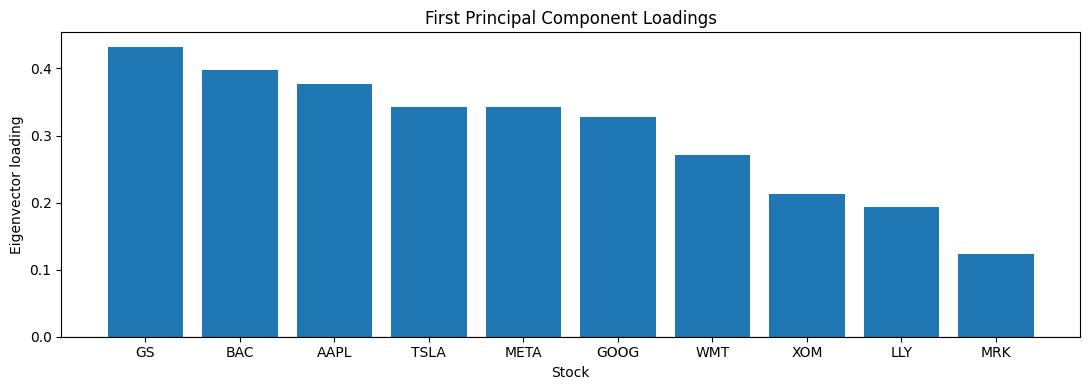

In [18]:
# Plot loadings
plt.figure(figsize=(11, 4))
plt.bar(pc1_table.index, pc1_table['PC1_Loading'])
plt.axhline(0, color='black', linewidth=0.8)
plt.title('First Principal Component Loadings')
plt.ylabel('Eigenvector loading')
plt.xlabel('Stock')
plt.tight_layout()
plt.show()

assert np.isclose(np.sum(pc1**2), 1)
assert np.isclose(pc1_table['PC1_Contribution_%'].sum(), 100)


* Five stocks (GS, BAC, AAPL, TSLA, and META) account for 72.13% of PC1's total variance contribution: 18.68% + 15.78% + 14.19% + 11.78% + 11.71% = 72.13% . Especially Financial companies Goldman sachs(Gs) and Bank of America appear to be the top2 largest contributors of our first principal component, does it mean it is not a market factor but acts as one since GS and BAC might have investments in each of the other stocks in our portfolio creating this halo like common correlation?
* The other stocks like  MRK, LLY, XOM have single digit, below 5% contribution each, so the contribution is almost entirely driven by finance-techishque companies.
* This pc1 is not representative of market factor or is it? does it atleast a representative of s&p 500?




## STEP 5B: Compare PC1 with the S&P 500
let's see how the pc1 of s&p 500 compares against our little portfolio pc1.

plans:
1. Get the s&p 500 data from sing chun lee's code.
2. get z scores for returns of our assets in train, so that highly volatile assets do not wag their tails too much and influence our analysis dispropotionately.
3. Get the pc1 scores by matrix multiplying our z score with pc1 we found above.
4. we want to compare this pc1 scores with our s&p 500 by seeing how much they are similar or correlate.


In [23]:
len(daily_returns.loc[train.index, BENCHMARK])

438

There are 438 stocks in our BENCHMARK, not 500 as the name implies, but that won't make our analysis any less better.

In [19]:
# s&p 500 is our benchmark
benchmark = daily_returns.loc[train.index, BENCHMARK]

standardized_returns = (
    train - train.mean()
) / train.std(ddof=1)

pc1_scores = pd.Series(
    standardized_returns.to_numpy() @ pc1,
    index=train.index,
    name='PC1'
)

comparison = pd.concat(
    [pc1_scores, benchmark.rename('SP500')],
    axis=1
).dropna()

pc1_sp500_corr = comparison['PC1'].corr(
    comparison['SP500']
)

print(f"Correlation between PC1 and S&P 500: "f"{pc1_sp500_corr:.4f}")



Correlation between PC1 and S&P 500: 0.9144


wow! that's a substantial correlation. Nice man, Our pc1 is indeed more similar to s&p 500 returns than not!!! the pc1 is a good enough representative of our common market factor.

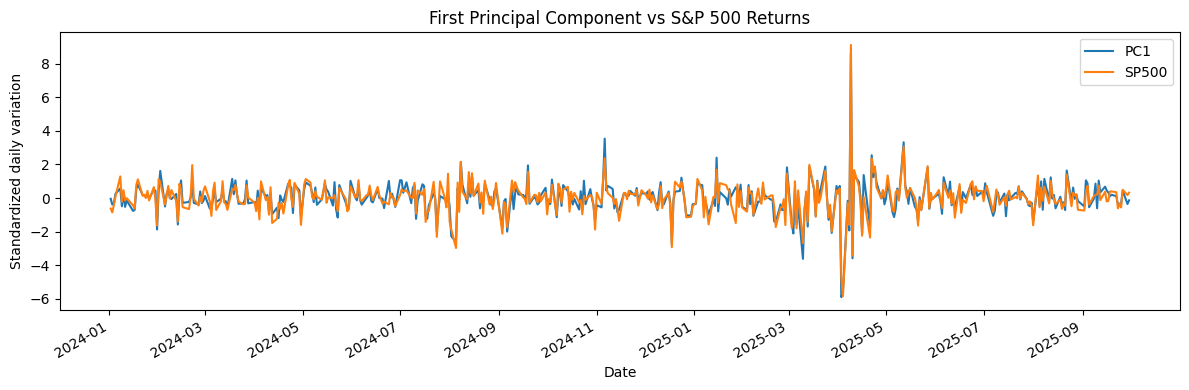

In [20]:
# Normalize for plotting only
normalized = (
    comparison - comparison.mean()
) / comparison.std()

normalized.plot(
    figsize=(12, 4),
    title='First Principal Component vs S&P 500 Returns'
)
plt.ylabel('Standardized daily variation')
plt.tight_layout()
plt.show()




## Step C: Which Stock's correlation change?

* Our previous table reported the average correlation, but that is insufficient to understand clustering, we want to which pair of stocks are strongly correlated after removing the first component; we want to inspect whether BAC–GS, LLY–MRK, and GOOG–META remain strongly related after removing the pc1.

* we have removed the effect of pc1 with denoising and detoning, so we'll compare the pair-wise correlation in each of these filtered and un-filtered versions of correlations.





In [24]:

# this is our raw correlation
raw_corr = pd.DataFrame(
    c_raw, index=tickers, columns=tickers
)

# correlation of c_tone or detoned correlation
detoned_corr = pd.DataFrame(
    c_tone, index=tickers, columns=tickers
)

# this is correlation of the matrix that underwent both denoising and detoning.
combined_corr = pd.DataFrame(
    c_dt, index=tickers, columns=tickers
)

# some unique pairs of our 10 stocks.
pairs = [
    ('BAC', 'GS'),
    ('LLY', 'MRK'),
    ('GOOG', 'META'),
    ('AAPL', 'GOOG'),
    ('TSLA', 'META'),
    ('WMT', 'XOM')
]

# create a beautiful DataFrame for it.
pair_table = pd.DataFrame([
    {
        'Pair': f'{a}-{b}',
        'Raw': raw_corr.loc[a, b],
        'Detoned': detoned_corr.loc[a, b],
        'Denoised_Detoned': combined_corr.loc[a, b],
        'Change_after_Detoning':
            detoned_corr.loc[a, b] - raw_corr.loc[a, b]
    }
    for a, b in pairs
]).set_index('Pair')

display(pair_table.round(4))


,Raw,Detoned,Denoised_Detoned,Change_after_Detoning
Pair,,,,
BAC-GS,0.7779,0.4402,-0.1342,-0.3377
LLY-MRK,0.3218,0.2621,-0.0488,-0.0598
GOOG-META,0.4477,0.0845,-0.1312,-0.3632
AAPL-GOOG,0.4562,0.0349,-0.1336,-0.4213
TSLA-META,0.3310,-0.1448,-0.1327,-0.4758
WMT-XOM,0.0617,-0.1808,-0.0956,-0.2425


After just detoning we see the correlation between some assets still maintaining positive numbers but when denoised and detoned relationship between different assets in our portfolio became completely negative as if one would help hedge the other? But will it work in portfolio of any size, our portfolio had only 10 assets in them

Compare original and transformed correlation structures


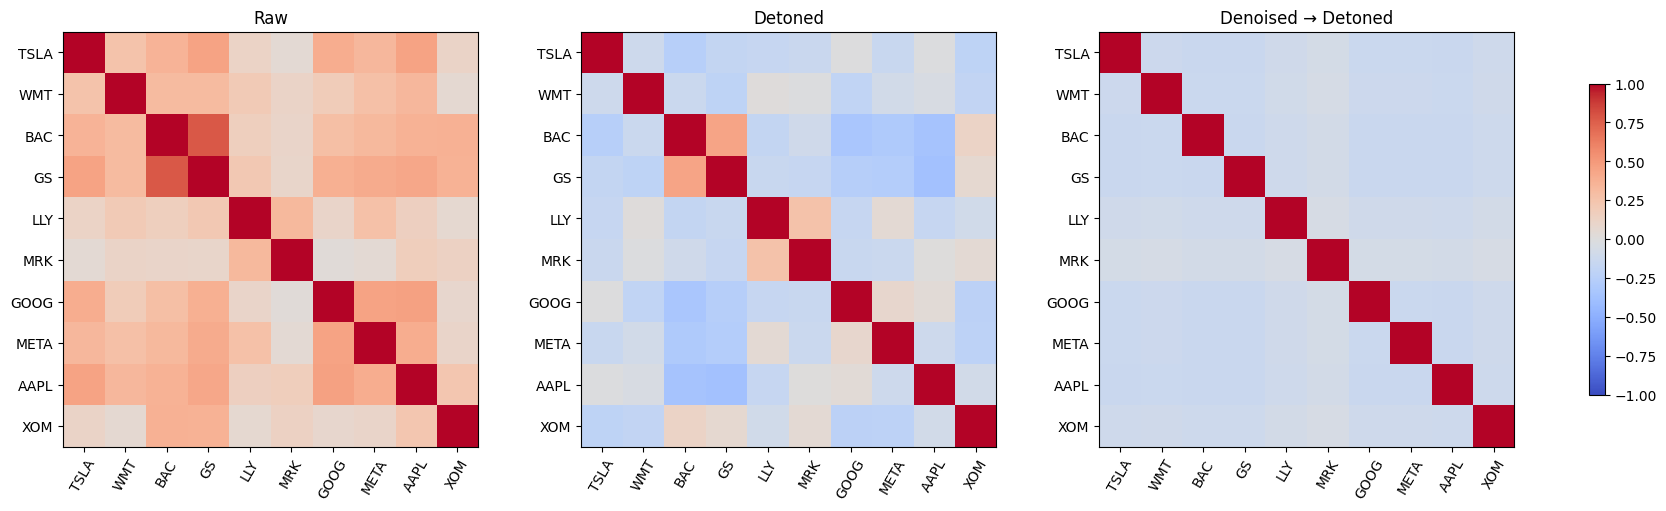

In [25]:


fig, axes = plt.subplots(
    1, 3, figsize=(17, 5), constrained_layout=True
)

for ax, (name, matrix) in zip(
    axes,
    [
        ('Raw', c_raw),
        ('Detoned', c_tone),
        ('Denoised → Detoned', c_dt)
    ]
):
    im = ax.imshow(
        matrix, cmap='coolwarm',
        vmin=-1, vmax=1
    )
    ax.set_title(name)
    ax.set_xticks(range(len(tickers)))
    ax.set_yticks(range(len(tickers)))
    ax.set_xticklabels(tickers, rotation=60)
    ax.set_yticklabels(tickers)

fig.colorbar(im, ax=axes, shrink=0.75)
plt.show()


They behave like completely different opposing entities after denoising and detoned.